In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# --------------------------------------------------
# Find project root
# --------------------------------------------------

cwd = Path.cwd()

if (cwd / "tables1").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "tables1").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not locate project root.")

print("PROJECT_ROOT:", PROJECT_ROOT)

# --------------------------------------------------
# Load YFF Bayesian Lambda matrix
# --------------------------------------------------

lambda_dir = (
    PROJECT_ROOT
    / "tables1"
    / "gamma_poisson"
    / "lambda_matrices"
)

lambda_path = lambda_dir / "YFF_lambda.npy"

Lambda = np.load(lambda_path)

print("\nYFF Lambda loaded successfully.")
print("Shape:", Lambda.shape)
print("Data type:", Lambda.dtype)

# --------------------------------------------------
# Basic checks
# --------------------------------------------------

print("\nBasic checks")
print("All finite:", np.isfinite(Lambda).all())
print("Any negative values:", (Lambda < 0).any())

print("\nValue summary")
print("Minimum:", Lambda.min())
print("Maximum:", Lambda.max())
print("Mean:", Lambda.mean())
print("Median:", np.median(Lambda))

# --------------------------------------------------
# Mean posterior rate for each number
# --------------------------------------------------

row_means = Lambda.mean(axis=1)

print("\nMean Lambda across features for each number")

for number, value in enumerate(row_means, start=1):
    print(f"Number {number}: {value:.6f}")

PROJECT_ROOT: c:\Users\shafi\number-simplex-reproduction

YFF Lambda loaded successfully.
Shape: (9, 333)
Data type: float64

Basic checks
All finite: True
Any negative values: False

Value summary
Minimum: 0.011111111111111112
Maximum: 2.7038461538461536
Mean: 0.6487734143954188
Median: 0.7038461538461539

Mean Lambda across features for each number
Number 1: 0.598634
Number 2: 0.799748
Number 3: 0.632904
Number 4: 0.550062
Number 5: 0.474457
Number 6: 0.714472
Number 7: 0.730497
Number 8: 0.665152
Number 9: 0.673036


In [2]:
# --------------------------------------------------
# Step 2: Center the Bayesian number representations
# --------------------------------------------------

# Centroid of the 9 number representations
lambda_centroid = Lambda.mean(axis=0, keepdims=True)

# Center each number representation
C = Lambda - lambda_centroid

print("Original Lambda shape:", Lambda.shape)
print("Centered matrix C shape:", C.shape)

# --------------------------------------------------
# Verify centering
# --------------------------------------------------

print("\nMaximum absolute column mean after centering:")
print(np.abs(C.mean(axis=0)).max())

# --------------------------------------------------
# Distance of each number from the global centroid
# --------------------------------------------------

centroid_distances = np.linalg.norm(C, axis=1)

print("\nDistance of each number from the centroid:")

for number, distance in enumerate(centroid_distances, start=1):
    print(f"Number {number}: {distance:.6f}")

print("\nCentroid-distance summary")
print("Mean:", centroid_distances.mean())
print("SD:", centroid_distances.std())
print("Minimum:", centroid_distances.min())
print("Maximum:", centroid_distances.max())

Original Lambda shape: (9, 333)
Centered matrix C shape: (9, 333)

Maximum absolute column mean after centering:
2.837236618486511e-16

Distance of each number from the centroid:
Number 1: 3.275169
Number 2: 4.695488
Number 3: 3.030523
Number 4: 4.618215
Number 5: 4.850224
Number 6: 3.587604
Number 7: 3.785579
Number 8: 2.970600
Number 9: 3.192666

Centroid-distance summary
Mean: 3.7784520895877276
SD: 0.7102257848015948
Minimum: 2.9706002616630567
Maximum: 4.850223926730397


In [3]:
# --------------------------------------------------
# Step 3: SVD and dimensionality of Bayesian geometry
# --------------------------------------------------

U, singular_values, Vt = np.linalg.svd(
    C,
    full_matrices=False
)

# Variance associated with each singular direction
variance = singular_values**2

explained_variance_ratio = variance / variance.sum()
cumulative_variance = np.cumsum(explained_variance_ratio)

# Numerical matrix rank
numerical_rank = np.linalg.matrix_rank(C)

print("Centered matrix shape:", C.shape)
print("Maximum possible affine rank:", 8)
print("Numerical rank:", numerical_rank)

print("\nSingular-value spectrum")

for i, (s, evr, cum) in enumerate(
    zip(
        singular_values,
        explained_variance_ratio,
        cumulative_variance
    ),
    start=1
):
    print(
        f"Dimension {i}: "
        f"singular value = {s:.6f}, "
        f"variance = {100 * evr:.2f}%, "
        f"cumulative = {100 * cum:.2f}%"
    )

# --------------------------------------------------
# Effective dimensionality
# --------------------------------------------------

p = explained_variance_ratio[
    explained_variance_ratio > 0
]

effective_rank = np.exp(
    -np.sum(p * np.log(p))
)

participation_ratio = 1 / np.sum(p**2)

print("\nEffective dimensionality")
print("Effective rank:", effective_rank)
print("Participation ratio:", participation_ratio)

Centered matrix shape: (9, 333)
Maximum possible affine rank: 8
Numerical rank: 8

Singular-value spectrum
Dimension 1: singular value = 7.185431, variance = 38.81%, cumulative = 38.81%
Dimension 2: singular value = 4.408285, variance = 14.61%, cumulative = 53.42%
Dimension 3: singular value = 3.679592, variance = 10.18%, cumulative = 63.60%
Dimension 4: singular value = 3.431431, variance = 8.85%, cumulative = 72.45%
Dimension 5: singular value = 3.292445, variance = 8.15%, cumulative = 80.60%
Dimension 6: singular value = 3.138308, variance = 7.40%, cumulative = 88.00%
Dimension 7: singular value = 2.915446, variance = 6.39%, cumulative = 94.39%
Dimension 8: singular value = 2.731954, variance = 5.61%, cumulative = 100.00%
Dimension 9: singular value = 0.000000, variance = 0.00%, cumulative = 100.00%

Effective dimensionality
Effective rank: 6.233224623969974
Participation ratio: 4.772958494323755


In [4]:
# --------------------------------------------------
# Step 3: SVD and dimensionality
# --------------------------------------------------

U, singular_values, Vt = np.linalg.svd(
    C,
    full_matrices=False
)

# Variance carried by each singular direction
variance = singular_values**2

explained_variance_ratio = variance / variance.sum()
cumulative_variance = np.cumsum(explained_variance_ratio)

# Numerical rank
numerical_rank = np.linalg.matrix_rank(C)

print("Centered matrix shape:", C.shape)
print("Maximum possible affine rank:", 8)
print("Numerical rank:", numerical_rank)

print("\nSingular-value spectrum")

for i, (s, evr, cum) in enumerate(
    zip(
        singular_values,
        explained_variance_ratio,
        cumulative_variance
    ),
    start=1
):
    print(
        f"Dimension {i}: "
        f"singular value = {s:.6f}, "
        f"variance = {100 * evr:.2f}%, "
        f"cumulative = {100 * cum:.2f}%"
    )

# --------------------------------------------------
# Effective dimensionality
# --------------------------------------------------

# Ignore the zero singular direction created by centering
p = explained_variance_ratio[
    explained_variance_ratio > 1e-12
]

effective_rank = np.exp(
    -np.sum(p * np.log(p))
)

participation_ratio = 1 / np.sum(p**2)

print("\nEffective dimensionality")
print("Effective rank:", effective_rank)
print("Participation ratio:", participation_ratio)

Centered matrix shape: (9, 333)
Maximum possible affine rank: 8
Numerical rank: 8

Singular-value spectrum
Dimension 1: singular value = 7.185431, variance = 38.81%, cumulative = 38.81%
Dimension 2: singular value = 4.408285, variance = 14.61%, cumulative = 53.42%
Dimension 3: singular value = 3.679592, variance = 10.18%, cumulative = 63.60%
Dimension 4: singular value = 3.431431, variance = 8.85%, cumulative = 72.45%
Dimension 5: singular value = 3.292445, variance = 8.15%, cumulative = 80.60%
Dimension 6: singular value = 3.138308, variance = 7.40%, cumulative = 88.00%
Dimension 7: singular value = 2.915446, variance = 6.39%, cumulative = 94.39%
Dimension 8: singular value = 2.731954, variance = 5.61%, cumulative = 100.00%
Dimension 9: singular value = 0.000000, variance = 0.00%, cumulative = 100.00%

Effective dimensionality
Effective rank: 6.233224623969974
Participation ratio: 4.772958494323755


In [5]:
# --------------------------------------------------
# Step 4: Pairwise Euclidean distances
# --------------------------------------------------

# Compute pairwise differences between all 9 number vectors
differences = Lambda[:, None, :] - Lambda[None, :, :]

# Euclidean norm across the 333 features
D = np.linalg.norm(differences, axis=2)

# Labels 1 through 9
numbers = np.arange(1, 10)

# Put distance matrix into a readable table
D_df = pd.DataFrame(
    D,
    index=numbers,
    columns=numbers
)

print("Pairwise Euclidean distance matrix:\n")
print(D_df.round(3))

# --------------------------------------------------
# Extract the 36 unique distances
# --------------------------------------------------

upper_triangle = np.triu_indices(9, k=1)

edge_distances = D[upper_triangle]

print("\nPairwise-distance summary")
print("Number of unique pairs:", len(edge_distances))
print("Mean distance:", edge_distances.mean())
print("SD:", edge_distances.std())
print("Minimum:", edge_distances.min())
print("Maximum:", edge_distances.max())

# Relative variability of pairwise distances
edge_cv = edge_distances.std() / edge_distances.mean()

print("Coefficient of variation:", edge_cv)
print(
    "Maximum / Minimum:",
    edge_distances.max() / edge_distances.min()
)

# --------------------------------------------------
# Identify closest and farthest pairs
# --------------------------------------------------

pair_i = upper_triangle[0]
pair_j = upper_triangle[1]

min_idx = np.argmin(edge_distances)
max_idx = np.argmax(edge_distances)

closest_pair = (
    pair_i[min_idx] + 1,
    pair_j[min_idx] + 1
)

farthest_pair = (
    pair_i[max_idx] + 1,
    pair_j[max_idx] + 1
)

print("\nClosest pair:", closest_pair)
print(
    "Closest distance:",
    edge_distances[min_idx]
)

print("\nFarthest pair:", farthest_pair)
print(
    "Farthest distance:",
    edge_distances[max_idx]
)

Pairwise Euclidean distance matrix:

       1      2      3      4      5      6      7      8      9
1  0.000  6.565  4.656  5.300  5.377  5.408  5.616  4.679  5.012
2  6.565  0.000  6.282  7.735  8.815  5.335  4.961  5.456  5.342
3  4.656  6.282  0.000  5.650  5.404  4.784  5.175  4.476  4.870
4  5.300  7.735  5.650  0.000  5.741  6.825  7.253  5.835  6.242
5  5.377  8.815  5.404  5.741  0.000  7.060  7.089  6.074  6.244
6  5.408  5.335  4.784  6.825  7.060  0.000  4.999  4.756  4.924
7  5.616  4.961  5.175  7.253  7.089  4.999  0.000  5.159  4.961
8  4.679  5.456  4.476  5.835  6.074  4.756  5.159  0.000  4.537
9  5.012  5.342  4.870  6.242  6.244  4.924  4.961  4.537  0.000

Pairwise-distance summary
Number of unique pairs: 36
Mean distance: 5.683182231958062
SD: 0.9792658732166267
Minimum: 4.476097515718541
Maximum: 8.814638745941506
Coefficient of variation: 0.17230942687530787
Maximum / Minimum: 1.9692687022540227

Closest pair: (np.int64(3), np.int64(8))
Closest distance: 4.476

In [6]:
np.linalg.matrix_rank(D)

np.int64(9)

In [7]:
# --------------------------------------------------
# Step 5A: PCA coordinates from the existing SVD
# --------------------------------------------------

# PCA scores / coordinates of the 9 number representations
Z = U * singular_values

print("PCA coordinate matrix shape:", Z.shape)

# Show first 3 PCs
pca_coordinates = pd.DataFrame(
    Z[:, :3],
    index=np.arange(1, 10),
    columns=["PC1", "PC2", "PC3"]
)

print("\nPCA coordinates for numbers 1-9:\n")
print(pca_coordinates.round(4))


PCA coordinate matrix shape: (9, 9)

PCA coordinates for numbers 1-9:

      PC1     PC2     PC3
1 -1.2377  0.1359 -0.0038
2  4.0079  1.4532 -0.8342
3 -0.6274 -0.8600  1.1857
4 -3.0097  3.2340 -0.1177
5 -4.0571 -1.9039 -0.8354
6  1.6613 -0.6175  2.6135
7  2.1583 -1.4034 -1.5819
8  0.3334  0.2336  0.5940
9  0.7710 -0.2720 -1.0201


Variance explained
PC1: 38.81%
PC2: 14.61%
PC1 + PC2: 53.42%


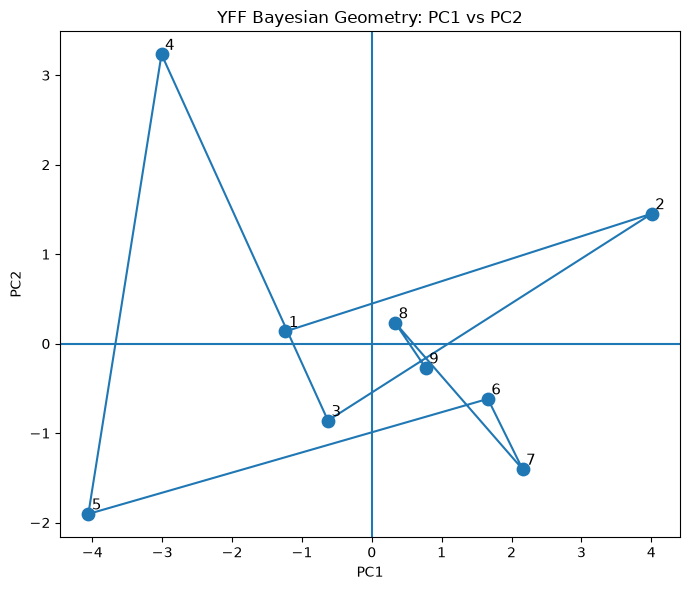

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# Step 5B: PC1 vs PC2 plot
# --------------------------------------------------

pc1 = Z[:, 0]
pc2 = Z[:, 1]

print("Variance explained")
print(f"PC1: {100 * explained_variance_ratio[0]:.2f}%")
print(f"PC2: {100 * explained_variance_ratio[1]:.2f}%")
print(f"PC1 + PC2: {100 * (explained_variance_ratio[0] + explained_variance_ratio[1]):.2f}%")

numbers = np.arange(1, 10)

plt.figure(figsize=(7, 6))
plt.scatter(pc1, pc2, s=80)

# label each point
for i, num in enumerate(numbers):
    plt.text(pc1[i] + 0.05, pc2[i] + 0.05, str(num), fontsize=11)

# connect numbers in numerical order
plt.plot(pc1, pc2)

# axis lines through origin
plt.axhline(0)
plt.axvline(0)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("YFF Bayesian Geometry: PC1 vs PC2")
plt.tight_layout()
plt.show()

Variance explained
PC1: 38.81%
PC3: 10.18%
PC1 + PC3: 48.99%


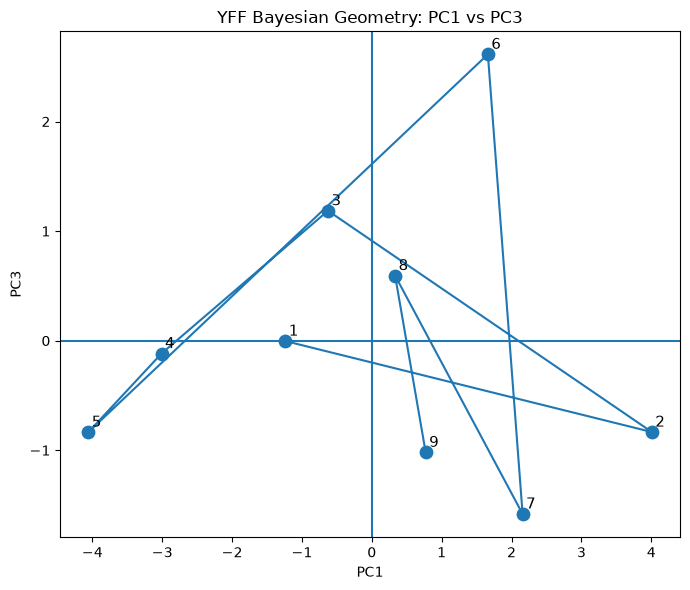

In [9]:
# --------------------------------------------------
# Step 5C: PC1 vs PC3
# --------------------------------------------------

pc1 = Z[:, 0]
pc3 = Z[:, 2]

print("Variance explained")
print(f"PC1: {100 * explained_variance_ratio[0]:.2f}%")
print(f"PC3: {100 * explained_variance_ratio[2]:.2f}%")
print(
    f"PC1 + PC3: "
    f"{100 * (explained_variance_ratio[0] + explained_variance_ratio[2]):.2f}%"
)

numbers = np.arange(1, 10)

plt.figure(figsize=(7, 6))

plt.scatter(
    pc1,
    pc3,
    s=80
)

# Number labels
for i, num in enumerate(numbers):
    plt.text(
        pc1[i] + 0.05,
        pc3[i] + 0.05,
        str(num),
        fontsize=11
    )

# Connect canonical numerical order
plt.plot(
    pc1,
    pc3
)

# Origin
plt.axhline(0)
plt.axvline(0)

plt.xlabel("PC1")
plt.ylabel("PC3")
plt.title("YFF Bayesian Geometry: PC1 vs PC3")

plt.tight_layout()
plt.show()

Variance explained
PC1: 38.81%
PC2: 14.61%
PC3: 10.18%
PC1 + PC2 + PC3: 63.60%


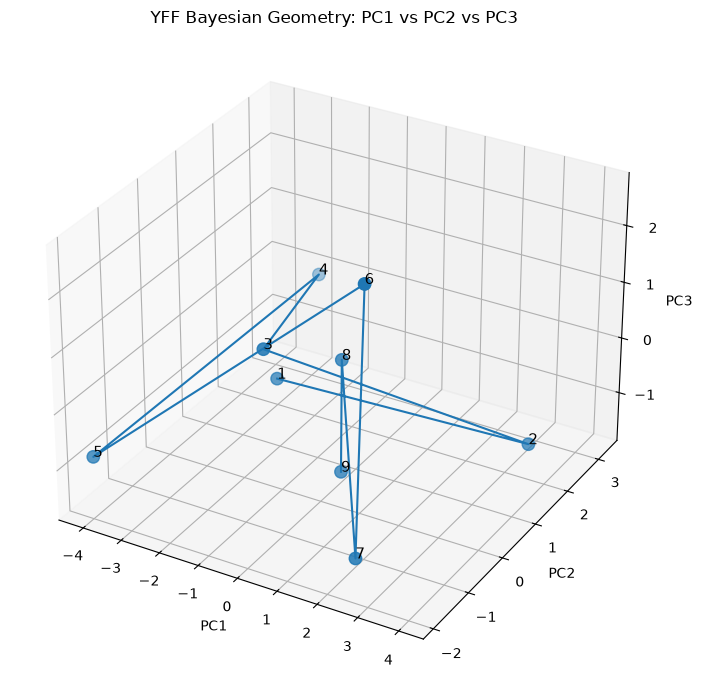

In [10]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# Step 5D: 3D PCA plot
# --------------------------------------------------

pc1 = Z[:, 0]
pc2 = Z[:, 1]
pc3 = Z[:, 2]

numbers = np.arange(1, 10)

print("Variance explained")
print(f"PC1: {100 * explained_variance_ratio[0]:.2f}%")
print(f"PC2: {100 * explained_variance_ratio[1]:.2f}%")
print(f"PC3: {100 * explained_variance_ratio[2]:.2f}%")
print(
    f"PC1 + PC2 + PC3: "
    f"{100 * (explained_variance_ratio[0] + explained_variance_ratio[1] + explained_variance_ratio[2]):.2f}%"
)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

# scatter points
ax.scatter(pc1, pc2, pc3, s=80)

# labels
for i, num in enumerate(numbers):
    ax.text(
        pc1[i],
        pc2[i],
        pc3[i],
        str(num),
        fontsize=11
    )

# connect canonical numerical order
ax.plot(pc1, pc2, pc3)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("YFF Bayesian Geometry: PC1 vs PC2 vs PC3")

plt.tight_layout()
plt.show()

In [11]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
# --------------------------------------------------
# Fun visualization: Interactive 3D PCA geometry
# --------------------------------------------------

import numpy as np
import plotly.graph_objects as go

pc1 = Z[:, 0]
pc2 = Z[:, 1]
pc3 = Z[:, 2]

numbers = np.arange(1, 10)

# --------------------------------------------------
# Number points
# --------------------------------------------------

fig = go.Figure()

fig.add_trace(
    go.Scatter3d(
        x=pc1,
        y=pc2,
        z=pc3,
        mode="markers+text",
        text=[str(n) for n in numbers],
        textposition="top center",
        marker=dict(
            size=7
        ),
        name="Numbers"
    )
)

# --------------------------------------------------
# Numerical-order trajectory: 1 -> 2 -> ... -> 9
# --------------------------------------------------

fig.add_trace(
    go.Scatter3d(
        x=pc1,
        y=pc2,
        z=pc3,
        mode="lines",
        name="1 → 9 path"
    )
)

# --------------------------------------------------
# Layout
# --------------------------------------------------

fig.update_layout(
    title=(
        "YFF Bayesian Geometry<br>"
        "PC1–PC2–PC3 "
        "(63.60% variance explained)"
    ),

    scene=dict(
        xaxis_title="PC1 (38.81%)",
        yaxis_title="PC2 (14.61%)",
        zaxis_title="PC3 (10.18%)",

        aspectmode="data"
    ),

    width=850,
    height=750
)

fig.show()

In [15]:
# --------------------------------------------------
# Step 6A: Empirical Gram matrix
# --------------------------------------------------

G = C @ C.T

numbers = np.arange(1, 10)

G_df = pd.DataFrame(
    G,
    index=numbers,
    columns=numbers
)

print("Gram matrix shape:", G.shape)

print("\nEmpirical Gram matrix:\n")
print(G_df.round(3))

# --------------------------------------------------
# Basic checks
# --------------------------------------------------

print("\nSymmetry check:")
print(
    np.allclose(
        G,
        G.T
    )
)

print("\nRank of Gram matrix:")
print(
    np.linalg.matrix_rank(G)
)

# --------------------------------------------------
# Diagonal = squared centroid distances
# --------------------------------------------------

gram_diagonal = np.diag(G)

print("\nDiagonal entries:")

for number, value in enumerate(
    gram_diagonal,
    start=1
):
    print(
        f"Number {number}: "
        f"{value:.6f}"
    )

print(
    "\nCheck against squared centroid distances:",
    np.allclose(
        gram_diagonal,
        centroid_distances**2
    )
)

Gram matrix shape: (9, 9)

Empirical Gram matrix:

        1       2      3       4       5       6       7      8       9
1  10.727  -5.162 -0.883   1.985   2.668  -2.824  -3.238 -1.170  -2.102
2  -5.162  22.048 -4.116  -8.224 -16.063   3.229   5.883  0.552   1.853
3  -0.883  -4.116  9.184  -0.704   1.754  -0.416  -1.634 -1.013  -2.170
4   1.985  -8.224 -0.704  21.328   5.949  -6.191  -8.474 -1.946  -3.723
5   2.668 -16.063  1.754   5.949  23.525  -6.724  -6.201 -2.273  -2.634
6  -2.824   3.229 -0.416  -6.191  -6.724  12.871   1.107 -0.461  -0.591
7  -3.238   5.883 -1.634  -8.474  -6.201   1.107  14.331 -1.730  -0.042
8  -1.170   0.552 -1.013  -1.946  -2.273  -0.461  -1.730  8.824  -0.783
9  -2.102   1.853 -2.170  -3.723  -2.634  -0.591  -0.042 -0.783  10.193

Symmetry check:
True

Rank of Gram matrix:
8

Diagonal entries:
Number 1: 10.726730
Number 2: 22.047609
Number 3: 9.184070
Number 4: 21.327906
Number 5: 23.524672
Number 6: 12.870905
Number 7: 14.330611
Number 8: 8.824466
Number

In [16]:
# --------------------------------------------------
# Step 6B: Matched ideal regular-simplex Gram matrix
# --------------------------------------------------

n_vertices = 9

# Mean squared radius of empirical geometry
r2_match = np.mean(np.diag(G))
r_match = np.sqrt(r2_match)

print("Matched squared radius:", r2_match)
print("Matched radius:", r_match)

# --------------------------------------------------
# Construct ideal regular-simplex Gram matrix
# --------------------------------------------------

G_ideal = np.full(
    (n_vertices, n_vertices),
    -r2_match / (n_vertices - 1)
)

np.fill_diagonal(
    G_ideal,
    r2_match
)

G_ideal_df = pd.DataFrame(
    G_ideal,
    index=np.arange(1, 10),
    columns=np.arange(1, 10)
)

print("\nMatched ideal regular-simplex Gram matrix:\n")
print(G_ideal_df.round(3))

# --------------------------------------------------
# Basic checks
# --------------------------------------------------

print("\nIdeal Gram matrix rank:")
print(np.linalg.matrix_rank(G_ideal))

print("\nIdeal diagonal value:")
print(r2_match)

print("\nIdeal off-diagonal value:")
print(-r2_match / 8)

print("\nRow sums:")
print(np.round(G_ideal.sum(axis=1), 12))

Matched squared radius: 14.781120858706906
Matched radius: 3.8446223297883115

Matched ideal regular-simplex Gram matrix:

        1       2       3       4       5       6       7       8       9
1  14.781  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848
2  -1.848  14.781  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848
3  -1.848  -1.848  14.781  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848
4  -1.848  -1.848  -1.848  14.781  -1.848  -1.848  -1.848  -1.848  -1.848
5  -1.848  -1.848  -1.848  -1.848  14.781  -1.848  -1.848  -1.848  -1.848
6  -1.848  -1.848  -1.848  -1.848  -1.848  14.781  -1.848  -1.848  -1.848
7  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  14.781  -1.848  -1.848
8  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  14.781  -1.848
9  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  -1.848  14.781

Ideal Gram matrix rank:
8

Ideal diagonal value:
14.781120858706906

Ideal off-diagonal value:
-1.8476401073383633

Row sums:
[-0. -0. -

In [17]:
# --------------------------------------------------
# Step 6C: Deviation from matched regular simplex
# --------------------------------------------------

# Difference between empirical and ideal Gram matrices
G_difference = G - G_ideal

# Frobenius norms
difference_norm = np.linalg.norm(
    G_difference,
    ord="fro"
)

ideal_norm = np.linalg.norm(
    G_ideal,
    ord="fro"
)

empirical_norm = np.linalg.norm(
    G,
    ord="fro"
)

# Relative Gram deviation
relative_gram_error = (
    difference_norm / ideal_norm
)

print("Empirical Gram Frobenius norm:")
print(empirical_norm)

print("\nIdeal Gram Frobenius norm:")
print(ideal_norm)

print("\nDifference Frobenius norm:")
print(difference_norm)

print("\nRelative Gram error:")
print(relative_gram_error)

Empirical Gram Frobenius norm:
60.89141251279042

Ideal Gram Frobenius norm:
47.0332385672831

Difference Frobenius norm:
38.67348688282249

Relative Gram error:
0.8222586422046693


In [18]:
# --------------------------------------------------
# Diagonal vs off-diagonal deviation
# --------------------------------------------------

diag_empirical = np.diag(G)
diag_ideal = np.diag(G_ideal)

diag_rmse = np.sqrt(
    np.mean(
        (diag_empirical - diag_ideal)**2
    )
)

off_mask = ~np.eye(9, dtype=bool)

off_empirical = G[off_mask]
off_ideal = G_ideal[off_mask]

off_rmse = np.sqrt(
    np.mean(
        (off_empirical - off_ideal)**2
    )
)

print("Diagonal RMSE:")
print(diag_rmse)

print("\nOff-diagonal RMSE:")
print(off_rmse)

Diagonal RMSE:
5.580326259923388

Off-diagonal RMSE:
4.108558508317202


In [19]:
# --------------------------------------------------
# Step 7A: Centroid-based angular geometry
# --------------------------------------------------

# Norm of each centered number vector
radii = np.sqrt(np.diag(G))

# Cosine matrix
cosine_matrix = (
    G /
    np.outer(radii, radii)
)

# Numerical protection for arccos
cosine_matrix = np.clip(
    cosine_matrix,
    -1.0,
    1.0
)

# Convert to angles in degrees
angle_matrix = np.degrees(
    np.arccos(cosine_matrix)
)

# Diagonal is angle of a vector with itself
np.fill_diagonal(angle_matrix, 0.0)

angle_df = pd.DataFrame(
    angle_matrix,
    index=np.arange(1, 10),
    columns=np.arange(1, 10)
)

print("Centroid-angle matrix (degrees):\n")
print(angle_df.round(2))

# --------------------------------------------------
# 36 unique angles
# --------------------------------------------------

upper = np.triu_indices(9, k=1)

pairwise_angles = angle_matrix[upper]

print("\nAngular summary")
print("Number of unique angles:", len(pairwise_angles))
print("Mean angle:", pairwise_angles.mean())
print("SD:", pairwise_angles.std())
print("Minimum angle:", pairwise_angles.min())
print("Maximum angle:", pairwise_angles.max())

# --------------------------------------------------
# Acute / approximately orthogonal / obtuse
# --------------------------------------------------

print("\nAngle categories")
print(
    "Acute (< 90°):",
    np.sum(pairwise_angles < 90)
)

print(
    "Obtuse (> 90°):",
    np.sum(pairwise_angles > 90)
)

print(
    "Near orthogonal (85°–95°):",
    np.sum(
        (pairwise_angles >= 85)
        & (pairwise_angles <= 95)
    )
)

# --------------------------------------------------
# Most acute and most obtuse pairs
# --------------------------------------------------

min_idx = np.argmin(pairwise_angles)
max_idx = np.argmax(pairwise_angles)

pair_i = upper[0]
pair_j = upper[1]

most_acute_pair = (
    pair_i[min_idx] + 1,
    pair_j[min_idx] + 1
)

most_obtuse_pair = (
    pair_i[max_idx] + 1,
    pair_j[max_idx] + 1
)

print("\nMost acute pair:", most_acute_pair)
print("Angle:", pairwise_angles[min_idx])

print("\nMost obtuse pair:", most_obtuse_pair)
print("Angle:", pairwise_angles[max_idx])

Centroid-angle matrix (degrees):

        1       2       3       4       5       6       7      8       9
1    0.00  109.61   95.11   82.46   80.33  103.91  105.14  96.91  101.60
2  109.61    0.00  106.81  112.29  134.85   78.95   70.67  87.73   82.90
3   95.11  106.81    0.00   92.88   83.15   92.19   98.19  96.46  102.96
4   82.46  112.29   92.88    0.00   74.60  111.94  118.99  98.15  104.63
5   80.33  134.85   83.15   74.60    0.00  112.73  109.74  99.08   99.79
6  103.91   78.95   92.19  111.94  112.73    0.00   85.33  92.48   92.96
7  105.14   70.67   98.19  118.99  109.74   85.33    0.00  98.85   90.20
8   96.91   87.73   96.46   98.15   99.08   92.48   98.85   0.00   94.74
9  101.60   82.90  102.96  104.63   99.79   92.96   90.20  94.74    0.00

Angular summary
Number of unique angles: 36
Mean angle: 97.2031584765221
SD: 12.952287842537745
Minimum angle: 70.67260868512378
Maximum angle: 134.85437676660686

Angle categories
Acute (< 90°): 9
Obtuse (> 90°): 27
Near orthogonal (8

In [20]:
import math
import numpy as np

# --------------------------------------------------
# Step 8A: Volume and conditioning of YFF simplex
# --------------------------------------------------

# Use number 1 as the reference vertex
A = Lambda[1:, :] - Lambda[0, :]

print("Edge matrix shape:", A.shape)
print("Edge matrix rank:", np.linalg.matrix_rank(A))

# --------------------------------------------------
# Singular values of the 8 edge directions
# --------------------------------------------------

edge_singular_values = np.linalg.svd(
    A,
    compute_uv=False
)

print("\nEdge-matrix singular values:")

for i, s in enumerate(
    edge_singular_values,
    start=1
):
    print(
        f"s{i}: {s:.6f}"
    )

# --------------------------------------------------
# Condition number
# --------------------------------------------------

condition_number = (
    edge_singular_values[0]
    / edge_singular_values[-1]
)

print("\nCondition number:")
print(condition_number)

# --------------------------------------------------
# 8-dimensional simplex volume
# --------------------------------------------------

volume_8d = (
    np.prod(edge_singular_values)
    / math.factorial(8)
)

print("\n8D simplex volume:")
print(volume_8d)

# --------------------------------------------------
# Same volume using Gram determinant
# --------------------------------------------------

edge_gram = A @ A.T

volume_from_gram = (
    np.sqrt(
        np.linalg.det(edge_gram)
    )
    / math.factorial(8)
)

print("\nVolume from Gram determinant:")
print(volume_from_gram)

print(
    "\nVolume methods agree:",
    np.isclose(
        volume_8d,
        volume_from_gram
    )
)

Edge matrix shape: (8, 333)
Edge matrix rank: 8

Edge-matrix singular values:
s1: 10.771863
s2: 6.548261
s3: 4.405954
s4: 3.679592
s5: 3.431412
s6: 3.146825
s7: 2.923796
s8: 2.735031

Condition number:
3.9384790588386736

8D simplex volume:
2.4490112212020185

Volume from Gram determinant:
2.4490112212020265

Volume methods agree: True


In [21]:
# --------------------------------------------------
# Step 8B: Scale-free simplex shape measures
# --------------------------------------------------

import numpy as np
import math

# ==================================================
# 1. Reconstruct coordinates of matched regular simplex
#    from the ideal Gram matrix
# ==================================================

eigvals, eigvecs = np.linalg.eigh(G_ideal)

# Sort eigenvalues/eigenvectors from largest to smallest
idx = np.argsort(eigvals)[::-1]

eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]

# Keep the 8 nonzero dimensions
eigvals_8 = eigvals[:8]
eigvecs_8 = eigvecs[:, :8]

# Coordinates whose Gram matrix equals G_ideal
Z_ideal = (
    eigvecs_8
    @ np.diag(np.sqrt(eigvals_8))
)

print("Ideal simplex coordinate shape:", Z_ideal.shape)

# Verify reconstruction
G_ideal_reconstructed = Z_ideal @ Z_ideal.T

print(
    "Ideal Gram reconstruction correct:",
    np.allclose(
        G_ideal,
        G_ideal_reconstructed
    )
)

# ==================================================
# 2. Compute matched regular-simplex volume
# ==================================================

A_ideal = (
    Z_ideal[1:, :]
    - Z_ideal[0, :]
)

ideal_edge_singular_values = np.linalg.svd(
    A_ideal,
    compute_uv=False
)

volume_regular = (
    np.prod(ideal_edge_singular_values)
    / math.factorial(8)
)

print("\nEmpirical 8D volume:")
print(volume_8d)

print("\nMatched regular-simplex 8D volume:")
print(volume_regular)

# ==================================================
# 3. Normalized volume
# ==================================================

normalized_volume = (
    volume_8d / volume_regular
)

print("\nNormalized volume:")
print(normalized_volume)

# ==================================================
# 4. Symmetric anisotropy using centered geometry
# ==================================================

# First 8 singular values from centered C
sigma = singular_values[:8]

symmetric_condition_number = (
    sigma[0] / sigma[-1]
)

isotropy_ratio = (
    sigma[-1] / sigma[0]
)

print("\nSymmetric condition number:")
print(symmetric_condition_number)

print("\nIsotropy ratio:")
print(isotropy_ratio)

# ==================================================
# 5. Effective-rank normalization
# ==================================================

effective_rank_fraction = (
    effective_rank / 8
)

participation_ratio_fraction = (
    participation_ratio / 8
)

print("\nEffective-rank fraction:")
print(effective_rank_fraction)

print("\nParticipation-ratio fraction:")
print(participation_ratio_fraction)

Ideal simplex coordinate shape: (9, 8)
Ideal Gram reconstruction correct: True

Empirical 8D volume:
2.4490112212020185

Matched regular-simplex 8D volume:
5.6890571068632685

Normalized volume:
0.43047752469342165

Symmetric condition number:
2.6301434409074793

Isotropy ratio:
0.3802074002682415

Effective-rank fraction:
0.7791530779962468

Participation-ratio fraction:
0.5966198117904694
